# Poisson equation

The "hello world" of finite elements, after the first chapter of the
[FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/) ("Fundamentals").
Find $u$ with

$$ -\Delta u = f \quad \text{in } \Omega = (0,1)^2, \qquad u = u_D \quad \text{on } \partial\Omega . $$

We manufacture the solution $u_e = 1 + x^2 + 2y^2$, which gives $f = -6$ and
$u_D = u_e$.  Multiplying by a test function $v$ and integrating by parts leads to
the weak form: find $u \in V$ with $u = u_D$ on the boundary such that

$$ \int_\Omega \nabla u \cdot \nabla v \, dx = \int_\Omega f v \, dx \qquad \forall v \in V_0 . $$

## Mesh and function space

`from ngsufl import *` brings in the complete UFL language together with a front end
that follows the Firedrake API.  The mesh is an NGSolve mesh, and the function space is
NGSolve's hierarchical high order $H^1$ space, requested as `"CG"` of degree 2.

In [1]:
from ngsufl import *

mesh = UnitSquareMesh(8, 8)
V = FunctionSpace(mesh, "CG", 2)

## Variational problem

This part is plain UFL, character for character what one writes in Firedrake.

In [2]:
u, v = TrialFunction(V), TestFunction(V)
x = SpatialCoordinate(mesh)

u_e = 1 + x[0]**2 + 2 * x[1]**2
f = Constant(-6.0)

a = inner(grad(u), grad(v)) * dx
L = f * v * dx

## Boundary condition and solve

`"on_boundary"` means all boundaries.  As in Firedrake, the sides of the unit square
are numbered 1: $x = 0$, 2: $x = 1$, 3: $y = 0$, 4: $y = 1$ (used in `ds(...)` and
`DirichletBC`).  The names `"left"`, `"right"`, `"bottom"`, `"top"` also work, which
is an ngsufl extra.

In [3]:
bc = DirichletBC(V, u_e, "on_boundary")

uh = Function(V, name="u")
solve(a == L, uh, bcs=[bc])

## Check and plot

The exact solution is a quadratic polynomial, so second order elements reproduce it
up to round-off.

In [4]:
print("L2 error:", errornorm(u_e, uh))
print("H1 error:", errornorm(u_e, uh, "H1"))

L2 error: 5.224199976267513e-16
H1 error: 5.83446187877849e-15


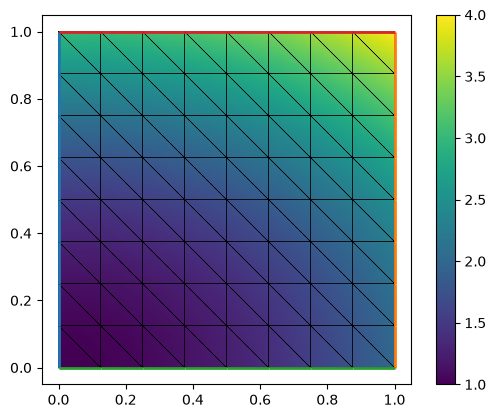

In [5]:
import matplotlib.pyplot as plt
from ngsufl.pyplot import tripcolor, triplot

fig, axes = plt.subplots()
colors = tripcolor(uh, axes=axes)
fig.colorbar(colors)
triplot(mesh, axes=axes, interior_kw={"linewidth": 0.3})
axes.set_aspect("equal");

## Behind the scenes (ngsufl extras)

The UFL form was translated to NGSolve CoefficientFunctions and assembled by NGSolve.
The function `uh` wraps an NGSolve `GridFunction`, available as `uh.gf`, and any UFL
expression can be turned into a CoefficientFunction with `to_cf`.  From there the
whole NGSolve toolbox is open.

In [6]:
import ngsolve

flux = to_cf(-grad(uh))
print(type(uh.gf).__name__, "with", V.dim(), "dofs")
print("flux at (0.5, 0.5):", flux(mesh.ngs(0.5, 0.5)))
print("energy:", ngsolve.Integrate(flux * flux, mesh.ngs))

GridFunction with 289 dofs
flux at (0.5, 0.5): (-1.0000000000000016, -2.0000000000000067)
energy: 6.6666666666666625
